# 6. Descriptive statistics and correlations

In this notebook we put all variables together in **one table with one row per municipality**. With that table we:

1. look at the descriptive statistics of each variable (mean, spread, minimum and maximum),
2. calculate how strongly each factor is related to charging point density,
3. check which explanatory variables are strongly related to each other.

The last step is important for the regression in notebook 7: if two explanatory variables measure almost the same thing, the regression cannot separate their effects (multicollinearity).

**Input** from `data/raw/`:
- `laadpunten_per_gemeente.csv`: regular public charging points per municipality, July 2026 (NAL)
- `inkomens_per_gemeente.csv`: households and standardised income per municipality, 2024 (CBS 86161NED)
- `kwb2024_per_gemeente.csv`: extract of CBS Kerncijfers wijken en buurten 2024 (85984NED), made by notebook 0.5; only used for the share of apartments

**Input** from `data/processed/` (made by the data processing notebooks):
- `age_per_municipality.csv`: share of residents aged 0–25 and 65+ (notebook 0.1)
- `education_per_municipality.csv`: share of highly educated residents (notebook 0.2)
- `left_wing_votes_per_municipality.csv`: left-wing vote share, broad and narrow definition (notebook 0.3)
- `population_density_per_municipality.csv`: population density (notebook 0.4)

**Output:**
- `data/processed/all_variables_per_municipality.csv`: the combined table, used in notebooks 6.2, 7 and 8
- `data/processed/table_comparison_factors.csv`: correlation of each factor with charging point density
- `figures/figure_distribution_of_public_charging_point_density.png` and `figures/figure_correlationmatrix.png`

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Folders, relative to the notebooks/ folder
RAW = "../data/raw/"
PROCESSED = "../data/processed/"
FIGURES = "../figures/"

## Step 1. Load the data and merge it into one table

We load the datasets one by one and add each one to a table called `df`. Each time we merge on the municipality name (`gemeente`).

There is one problem: the three sources do not always write a municipality name the same way. CBS writes *'s-Gravenhage (gemeente)* where the charging point file writes *Den Haag*, and the Kiesraad writes *Hengelo (O)* instead of *Hengelo*. If we merged without fixing this, these municipalities would get no match.

That is why we first make a dictionary `NAME_MAPPING` with the different spellings and the name we want to use instead. We always use the spelling of the charging point file. The function `clean_names` removes spaces before and after each name and then replaces the names from the dictionary. We use this function for every dataset.

In [ ]:
# standardize names
NAME_MAPPING = {
    "'s-Gravenhage (gemeente)": "Den Haag",
    "'s-Gravenhage": "Den Haag",
    "Groningen (gemeente)": "Groningen",
    "Utrecht (gemeente)": "Utrecht",
    "Beek (L.)": "Beek",
    "Stein (L.)": "Stein",
    "Hengelo (O.)": "Hengelo",
    "Hengelo (O)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
    "Bergen (L)": "Bergen (L.)",
    "Bergen (NH)": "Bergen (NH.)",
}


def clean_names(names):
    # remove spaces before and after the name, then replace the different spellings
    names = names.str.strip()
    names = names.replace(NAME_MAPPING)
    return names

### 1a. Charging points

The charging point file has two columns: the municipality and the number of regular public charging points. We give the columns short names. The last row is the national total (`Totaal`); that is not a municipality, so we remove it.

In [3]:
charging = pd.read_csv(RAW + "laadpunten_per_gemeente.csv", sep=";")
charging.columns = ["gemeente", "laadpunten"]

# Remove the row with the national total
charging = charging[charging["gemeente"] != "Totaal"]
charging["gemeente"] = clean_names(charging["gemeente"])

charging.head()

,gemeente,laadpunten
0,Aa en Hunze,89
1,Aalsmeer,316
2,Aalten,138
3,Achtkarspelen,54
4,Alblasserdam,183


### 1b. Households and income

From the CBS income file we need three columns: the number of households, the mean standardised income and the median standardised income. We rename them to short names.

The numbers in this file are stored as text with spaces in front (for example `"    42.6"`), and a missing value is written as a dot (`"."`). With `pd.to_numeric(..., errors="coerce")` we turn the text into numbers; the dots become `NaN` (missing).

In [4]:
income = pd.read_csv(RAW + "inkomens_per_gemeente.csv", sep=";", encoding="utf-8-sig")

income = income.rename(columns={
    "Regio's": "gemeente",
    "Particuliere huishoudens (x 1 000)": "huishoudens_x1000",
    "Inkomen/Gemiddeld gestandaardiseerd inkomen (1 000 euro)": "gem_gestandaardiseerd_inkomen_keur",
    "Inkomen/Mediaan gestandaardiseerd inkomen (1 000 euro)": "med_gestandaardiseerd_inkomen_keur",
})
income = income[["gemeente", "huishoudens_x1000",
                 "gem_gestandaardiseerd_inkomen_keur", "med_gestandaardiseerd_inkomen_keur"]]

# Text -> numbers; "." becomes NaN
for col in ["huishoudens_x1000", "gem_gestandaardiseerd_inkomen_keur", "med_gestandaardiseerd_inkomen_keur"]:
    income[col] = pd.to_numeric(income[col].astype(str).str.strip(), errors="coerce")

income["gemeente"] = clean_names(income["gemeente"])
income.head()

,gemeente,huishoudens_x1000,gem_gestandaardiseerd_inkomen_keur,med_gestandaardiseerd_inkomen_keur
0,Aa en Hunze,11.4,42.6,38.9
1,Aalsmeer,14.2,52.1,40.0
2,Aalten,11.7,40.5,36.4
3,Achtkarspelen,12.0,36.3,33.7
4,Alblasserdam,8.5,41.8,36.4


### 1c. Charging point density

Now we merge charging points and income into `df` and calculate the dependent variable:

$$\text{charging point density} = \frac{\text{charging points}}{\text{households}} \times 1000$$

CBS gives the number of households in thousands (`huishoudens_x1000`). So if we divide the charging points directly by this column, we already get charging points per 1,000 households.

We use `how="inner"`: only municipalities that are in both files are kept. We check with `len(df)` that all 342 municipalities are still there.

In [5]:
df = charging.merge(income, on="gemeente", how="inner")
df["laadpunten_per_1000_huishoudens"] = df["laadpunten"] / df["huishoudens_x1000"]

# Keep only the columns we need later
df = df[["gemeente", "laadpunten_per_1000_huishoudens",
         "gem_gestandaardiseerd_inkomen_keur", "med_gestandaardiseerd_inkomen_keur"]]

print("Number of municipalities:", len(df))
df.head()

Number of municipalities: 342


,gemeente,laadpunten_per_1000_huishoudens,gem_gestandaardiseerd_inkomen_keur,med_gestandaardiseerd_inkomen_keur
0,Aa en Hunze,7.807018,42.6,38.9
1,Aalsmeer,22.253521,52.1,40.0
2,Aalten,11.794872,40.5,36.4
3,Achtkarspelen,4.500000,36.3,33.7
4,Alblasserdam,21.529412,41.8,36.4


### 1d. Age structure

Notebook 0.1 has already combined the two CBS age files: the share of residents aged 0 to 25 and the share aged 65 and over, as a percentage of the total population. We give the columns the short names we use in this notebook.

From now on we merge with `how="left"`: all municipalities in `df` stay, also if a value is missing in the new file.

In [6]:
age = pd.read_csv(PROCESSED + "age_per_municipality.csv")
age.columns = ["gemeente", "jongeren_onder_25_pct", "ouderen_65plus_pct"]
age["gemeente"] = clean_names(age["gemeente"])

df = df.merge(age, on="gemeente", how="left")
df.head()

,gemeente,laadpunten_per_1000_huishoudens,gem_gestandaardiseerd_inkomen_keur,med_gestandaardiseerd_inkomen_keur,jongeren_onder_25_pct,ouderen_65plus_pct
0,Aa en Hunze,7.807018,42.6,38.9,22.8,29.8
1,Aalsmeer,22.253521,52.1,40.0,28.3,19.6
2,Aalten,11.794872,40.5,36.4,25.8,25.1
3,Achtkarspelen,4.500000,36.3,33.7,28.4,22.8
4,Alblasserdam,21.529412,41.8,36.4,30.3,20.9


### 1e. Left-wing vote share

Notebook 0.3 has already calculated the left-wing vote share per municipality as a percentage of all valid votes. It uses two definitions:
- **Broad** (main definition): GroenLinks-PvdA, SP, Partij voor de Dieren, DENK, BIJ1, D66 and Volt
- **Narrow** (to check whether the result depends on the definition): the same without D66 and Volt

In [7]:
votes = pd.read_csv(PROCESSED + "left_wing_votes_per_municipality.csv")
votes.columns = ["gemeente", "linkse_stemmen_pct", "linkse_stemmen_smal_pct"]
votes["gemeente"] = clean_names(votes["gemeente"])

df = df.merge(votes, on="gemeente", how="left")
df.head()

,gemeente,laadpunten_per_1000_huishoudens,gem_gestandaardiseerd_inkomen_keur,med_gestandaardiseerd_inkomen_keur,jongeren_onder_25_pct,ouderen_65plus_pct,linkse_stemmen_pct,linkse_stemmen_smal_pct
0,Aa en Hunze,7.807018,42.6,38.9,22.8,29.8,38.32,19.85
1,Aalsmeer,22.253521,52.1,40.0,28.3,19.6,28.42,11.60
2,Aalten,11.794872,40.5,36.4,25.8,25.1,24.21,11.38
3,Achtkarspelen,4.500000,36.3,33.7,28.4,22.8,15.92,8.76
4,Alblasserdam,21.529412,41.8,36.4,30.3,20.9,20.05,10.81


### 1f. Education, population density and share of apartments

These three variables come from CBS Kerncijfers wijken en buurten 2024.
- **Education:** notebook 0.2 has already calculated the share of highly educated residents:

$$\text{highly educated (\%)} = \frac{\text{high}}{\text{low} + \text{middle} + \text{high}} \times 100$$

  For Rozendaal, CBS does not publish the number of low educated residents, so this share is missing.
- **Population density:** prepared by notebook 0.4.
- **Share of apartments:** there is no processed file for this variable, so we take it directly from the extract `kwb2024_per_gemeente.csv` (notebook 0.5).

In [8]:
education = pd.read_csv(PROCESSED + "education_per_municipality.csv")
education = education[["municipality", "highly_educated_pct"]]
education.columns = ["gemeente", "hoogopgeleid_pct"]
education["gemeente"] = clean_names(education["gemeente"])

density = pd.read_csv(PROCESSED + "population_density_per_municipality.csv")
density = density[["municipality", "population_density"]]
density.columns = ["gemeente", "bevolkingsdichtheid"]
density["gemeente"] = clean_names(density["gemeente"])

kwb = pd.read_csv(RAW + "kwb2024_per_gemeente.csv")
kwb = kwb[["gemeente", "meergezinswoning_pct"]]
kwb["gemeente"] = clean_names(kwb["gemeente"])

df = df.merge(education, on="gemeente", how="left")
df = df.merge(density, on="gemeente", how="left")
df = df.merge(kwb, on="gemeente", how="left")

print("Number of municipalities:", len(df))
print("Variables:", list(df.columns[1:]))

Number of municipalities: 342
Variables: ['laadpunten_per_1000_huishoudens', 'gem_gestandaardiseerd_inkomen_keur', 'med_gestandaardiseerd_inkomen_keur', 'jongeren_onder_25_pct', 'ouderen_65plus_pct', 'linkse_stemmen_pct', 'linkse_stemmen_smal_pct', 'hoogopgeleid_pct', 'bevolkingsdichtheid', 'meergezinswoning_pct']


### 1g. Readable names and missing values

The column names in `df` are short and Dutch, which is handy in code but not in tables and figures. So we make a copy called `data` with readable English names. We use `data` for all tables and figures below; `df` keeps the short names and is saved at the end.

Then we count how many values are missing per variable, and look up which municipalities they are.

In [9]:
LABELS = {
    "laadpunten_per_1000_huishoudens": "Charging points per 1,000 households",
    "gem_gestandaardiseerd_inkomen_keur": "Mean standardised income (k€)",
    "med_gestandaardiseerd_inkomen_keur": "Median standardised income (k€)",
    "jongeren_onder_25_pct": "Residents under 25 (%)",
    "ouderen_65plus_pct": "Residents 65+ (%)",
    "linkse_stemmen_pct": "Left-wing vote share (%)",
    "linkse_stemmen_smal_pct": "Left-wing vote share, narrow (%)",
    "hoogopgeleid_pct": "Highly educated (%)",
    "bevolkingsdichtheid": "Population density (inh./km²)",
    "meergezinswoning_pct": "Apartments (% of dwellings)",
}
data = df[list(LABELS)].rename(columns=LABELS)

missing = data.isna().sum()
print(missing[missing > 0])

Mean standardised income (k€)      6
Median standardised income (k€)    3
Highly educated (%)                1
dtype: int64


In [ ]:
# Which municipalities have at least one missing value
df[df.isna().any(axis=1)]

,gemeente,laadpunten_per_1000_huishoudens,gem_gestandaardiseerd_inkomen_keur,med_gestandaardiseerd_inkomen_keur,jongeren_onder_25_pct,ouderen_65plus_pct,linkse_stemmen_pct,linkse_stemmen_smal_pct,hoogopgeleid_pct,bevolkingsdichtheid,meergezinswoning_pct
12,Ameland,2.222222,NaN,33.7,24.3,25.5,25.97,12.15,23.40,68,21
232,Renswoude,6.363636,NaN,39.7,33.8,17.0,9.50,4.19,21.74,313,14
243,Rozendaal,21.428571,NaN,NaN,29.1,23.6,46.35,15.86,NaN,66,2
248,Schiermonnikoog,6.666667,NaN,NaN,17.1,31.5,51.82,29.85,37.84,23,27
269,Terschelling,11.304348,NaN,36.2,23.8,26.1,40.19,20.18,28.76,56,23
296,Vlieland,8.571429,NaN,NaN,19.2,23.2,46.90,24.69,32.00,30,31


The missing values are all in small municipalities (mostly islands). CBS does not publish income figures for them, and for Rozendaal also not the number of low educated residents, to protect the privacy of the residents. We do not remove these municipalities: for each calculation below, a municipality is only left out if it misses one of the variables used in that calculation.

## Step 2. Descriptive statistics

With `describe()` we get for each variable: the number of municipalities with a value (N), the mean, the standard deviation (SD), the minimum, the quartiles (25%, median, 75%) and the maximum. We transpose the table (`.T`) so that every variable is one row, which is easier to read.

In [11]:
summary = data.describe().T
summary = summary.rename(columns={"count": "N", "std": "SD", "50%": "median"})
summary["N"] = summary["N"].astype(int)
summary.round(2)

,N,mean,SD,min,25%,median,75%,max
"Charging points per 1,000 households",342,15.01,6.77,0.54,9.95,13.54,19.32,42.88
Mean standardised income (k€),336,44.17,8.58,34.10,40.50,42.90,45.70,154.70
Median standardised income (k€),339,38.07,2.69,30.40,36.40,38.00,39.65,48.50
Residents under 25 (%),342,26.23,2.87,17.10,24.60,26.05,27.90,42.40
Residents 65+ (%),342,23.61,3.68,11.00,21.30,23.60,25.88,34.90
Left-wing vote share (%),342,31.04,10.96,1.94,24.04,30.00,36.23,71.24
"Left-wing vote share, narrow (%)",342,14.92,6.52,1.21,10.55,13.74,18.25,45.13
Highly educated (%),341,30.39,7.97,12.44,25.14,28.66,33.38,58.38
Population density (inh./km²),342,917.63,1090.64,23.00,249.00,479.00,1194.00,6868.00
Apartments (% of dwellings),342,23.90,13.23,2.00,15.00,20.00,30.00,87.00


To see how charging point density is spread over the municipalities, we make a histogram. The dashed red line shows the median.

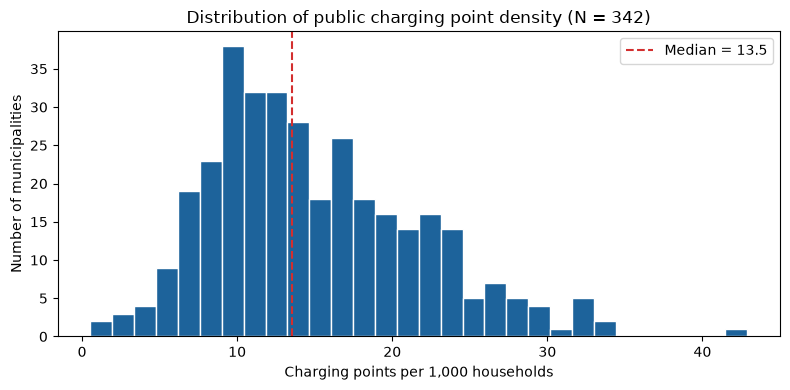

In [12]:
y = data["Charging points per 1,000 households"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y, bins=30, color="#1d639b", edgecolor="white")
ax.axvline(y.median(), color="#d32f2f", linestyle="--", label=f"Median = {y.median():.1f}")
ax.set_xlabel("Charging points per 1,000 households")
ax.set_ylabel("Number of municipalities")
ax.set_title(f"Distribution of public charging point density (N = {y.notna().sum()})")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES + "figure_distribution_of_public_charging_point_density.png", dpi=200)
plt.show()

## Step 3. How strongly is each factor related to charging point density?

For each explanatory variable we calculate:
- the **Pearson correlation r**: how strong the linear relation is, from −1 (perfectly negative) to +1 (perfectly positive);
- the **Spearman correlation ρ**: the same, but calculated on the ranks of the values instead of the values themselves. This makes it less sensitive to outliers and also works for relations that are not a straight line;
- the **p-value** of both: if p < 0.05, the relation is unlikely to be chance;
- **R² = r²**: the share of the differences in charging point density that this factor explains on its own.

We do this in a `for` loop over all columns. Per variable we first drop the municipalities with a missing value (`dropna`), so N can differ per variable. Each result is stored as a dictionary in the list `rows`, and at the end we turn that list into a table.

In [ ]:
# Which type of characteristic each variable is
GROUPS = {
    "Mean standardised income (k€)": "Socioeconomic",
    "Median standardised income (k€)": "Socioeconomic",
    "Highly educated (%)": "Socioeconomic",
    "Residents under 25 (%)": "Demographic",
    "Residents 65+ (%)": "Demographic",
    "Population density (inh./km²)": "Need",
    "Apartments (% of dwellings)": "Need",
    "Left-wing vote share (%)": "Political",
    "Left-wing vote share, narrow (%)": "Political",
}
target = "Charging points per 1,000 households"

rows = []
for col in data.columns:
    if col == target:
        continue                                 
    pair = data[[col, target]].dropna()
    r, p = stats.pearsonr(pair[col], pair[target])
    rho, p_rho = stats.spearmanr(pair[col], pair[target])
    rows.append({"Variable": col, "Group": GROUPS[col], "N": len(pair),
                 "Pearson r": r, "p (Pearson)": p,
                 "Spearman ρ": rho, "p (Spearman)": p_rho,
                 "R²": r ** 2})

corr_target = pd.DataFrame(rows)

# Strongest relation at the top
corr_target = corr_target.sort_values("R²", ascending=False)
corr_target.round(3)

,Variable,Group,N,Pearson r,p (Pearson),Spearman ρ,p (Spearman),R²
7,Population density (inh./km²),Need,342,0.411,0.000,0.514,0.000,0.169
8,Apartments (% of dwellings),Need,342,0.342,0.000,0.368,0.000,0.117
3,Residents 65+ (%),Demographic,342,-0.342,0.000,-0.381,0.000,0.117
1,Median standardised income (k€),Socioeconomic,339,0.337,0.000,0.336,0.000,0.113
6,Highly educated (%),Socioeconomic,341,0.301,0.000,0.332,0.000,0.091
2,Residents under 25 (%),Demographic,342,0.291,0.000,0.366,0.000,0.085
4,Left-wing vote share (%),Political,342,0.219,0.000,0.240,0.000,0.048
0,Mean standardised income (k€),Socioeconomic,336,0.174,0.001,0.336,0.000,0.030
5,"Left-wing vote share, narrow (%)",Political,342,0.154,0.004,0.141,0.009,0.024


In [14]:
# Save the table for the report
corr_target.round({"Pearson r": 3, "Spearman ρ": 3, "R²": 3}).to_csv(PROCESSED + "table_comparison_factors.csv", index=False)
print("Saved:", PROCESSED + "table_comparison_factors.csv")

Saved: ../data/processed/table_comparison_factors.csv


## Step 4. How are the explanatory variables related to each other?

The correlation matrix shows the correlation between every pair of variables. We use a colour scale that runs from blue (−1) through white (0) to red (+1), so strong negative and strong positive correlations both stand out.

If two explanatory variables have a correlation above about 0.7, they measure partly the same thing. In a regression it is then hard to tell which of the two has the effect (multicollinearity). That is why we also list these pairs separately.

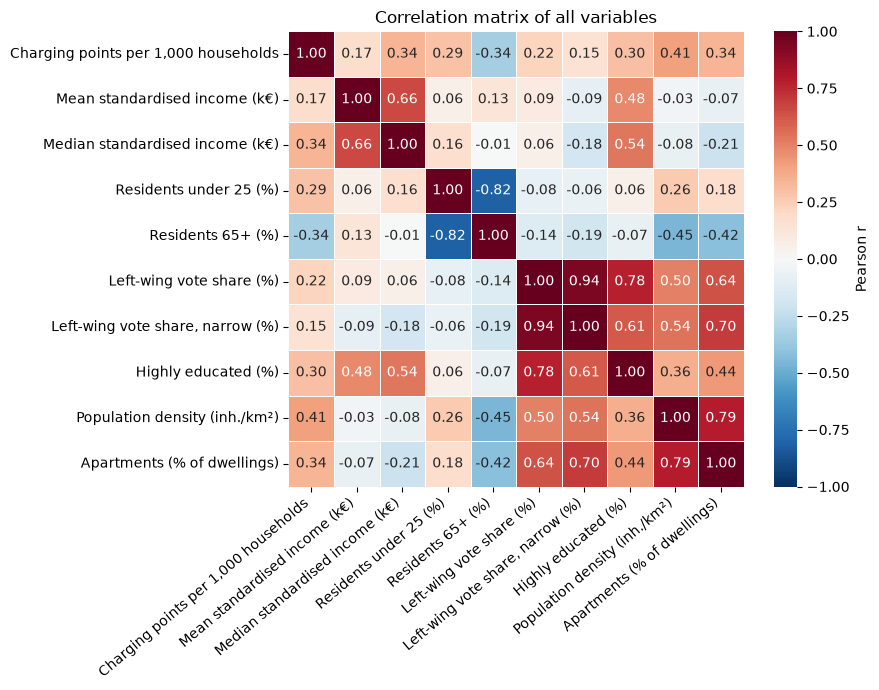

In [15]:
corr_matrix = data.corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix of all variables")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(FIGURES + "figure_correlationmatrix.png", dpi=200, bbox_inches="tight")
plt.show()

To find the pairs with |r| > 0.7 we go through the matrix with two `for` loops. The second loop starts at `i + 1`, so each pair is checked only once (A–B, and not again B–A).

In [16]:
explanatory = [col for col in data.columns if col != target]

pairs = []
for i in range(len(explanatory)):
    for j in range(i + 1, len(explanatory)):
        a = explanatory[i]
        b = explanatory[j]
        r = corr_matrix.loc[a, b]
        if abs(r) > 0.7:
            pairs.append({"Variable 1": a, "Variable 2": b, "Pearson r": round(r, 2)})

pd.DataFrame(pairs)

,Variable 1,Variable 2,Pearson r
0,Residents under 25 (%),Residents 65+ (%),-0.82
1,Left-wing vote share (%),"Left-wing vote share, narrow (%)",0.94
2,Left-wing vote share (%),Highly educated (%),0.78
3,"Left-wing vote share, narrow (%)",Apartments (% of dwellings),0.70
4,Population density (inh./km²),Apartments (% of dwellings),0.79


## Step 5. Save the combined table

We save `df`, with the short column names, so that notebooks 6.2, 7 and 8 can use it.

In [17]:
df.to_csv(PROCESSED + "all_variables_per_municipality.csv", index=False)
print("Saved:", PROCESSED + "all_variables_per_municipality.csv")

Saved: ../data/processed/all_variables_per_municipality.csv
